# Plotting Python model results with `anofox_viz`

A small online shop asks four questions of its data. Each one is answered
with an ordinary Python library, and each result is plotted with the
`anofox_plot_*` macros of the anofox_visualization DuckDB extension through
the [`anofox_viz`](../../python) helper package:

1. **What drives basket value?** statsmodels OLS: coefficients and residual diagnostics.
2. **Which customers will order again?** scikit-learn: ROC, precision–recall, calibration and summary metrics for two classifiers.
3. **Did the new checkout raise basket value?** scipy and pingouin tests.
4. **How many orders next month?** statsforecast: two models, nested 80 % / 95 % intervals and the shop's events on the same chart.

At the end the tables go to Parquet and a dashboard `.sql` file reads them.
All data is synthetic (seeded), so the notebook runs offline.

**Setup.** `pip install "duckdb==1.5.6" "anofox-viz @ git+https://github.com/DataZooDE/anofox-visualization#subdirectory=python" statsmodels scikit-learn scipy pingouin statsforecast pyarrow`.
`av.connect()` loads the extension from `$ANOFOX_VIZ_EXTENSION` (a file you
built or downloaded), else installs it.

In [1]:
import warnings

import numpy as np
import pandas as pd

import anofox_viz as av

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm, imported by statsforecast
con = av.connect()  # plot() uses this connection
rng = np.random.default_rng(2026)
con.execute("SELECT anofox_contract_version()").fetchone()

('1',)

## 1. What drives basket value? (statsmodels)

240 orders: the discount on the order, the ad spend of that day, weekend or
not, and whether the customer has ordered before.

In [2]:
import statsmodels.formula.api as smf

n = 240
orders = pd.DataFrame({
    "discount": rng.choice([0, 10, 20], n, p=[0.6, 0.25, 0.15]),  # percent
    "ad_spend": rng.gamma(4, 0.5, n).round(2),                      # k EUR that day
    "weekend": rng.random(n) < 2 / 7,
    "returning": rng.random(n) < 0.45,
    "variant": rng.choice(["A", "B"], n),                           # checkout A/B test
})
orders["basket"] = (
    38 + 0.45 * orders.discount + 1.8 * orders.ad_spend + 4.5 * orders.weekend
    + 7 * orders.returning + 2.5 * (orders.variant == "B")
    + rng.gamma(2, 6, n) - 12  # right-skewed noise
).round(2)

ols = smf.ols("basket ~ discount + ad_spend + weekend + returning", data=orders).fit()
basket = av.from_statsmodels(ols, model_id="ols")
basket["terms"][["term", "estimate", "conf_low", "conf_high", "p_value"]].round(3)

,term,estimate,conf_low,conf_high,p_value
0,Intercept,38.605,35.584,41.627,0.000
1,weekend[T.True],4.232,1.685,6.779,0.001
2,returning[T.True],8.612,6.367,10.857,0.000
3,discount,0.510,0.357,0.662,0.000
4,ad_spend,1.575,0.412,2.738,0.008


`from_statsmodels` returns contract tables (`terms`, `obs`, `summary`,
`prediction`) as pandas DataFrames, so they can be filtered before plotting:
without the intercept the effects share a readable scale.

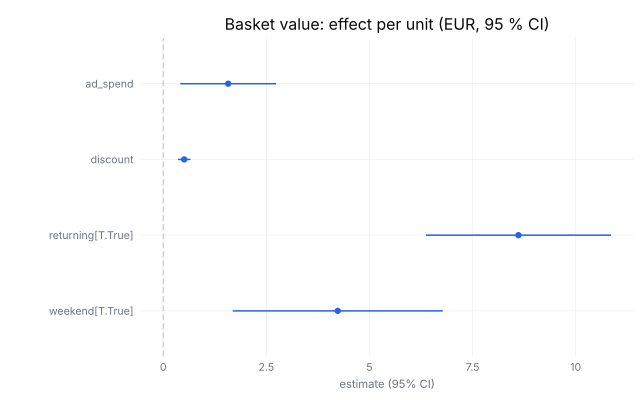

In [3]:
effects = basket["terms"].query("term != 'Intercept'")
av.plot(effects, "terms", title="Basket value: effect per unit (EUR, 95 % CI)")

The residual diagnostics (the `plot.lm` 2×2). The noise is right-skewed, so
the Q–Q panel bends upward at the top: the intervals above are slightly
optimistic for large baskets.

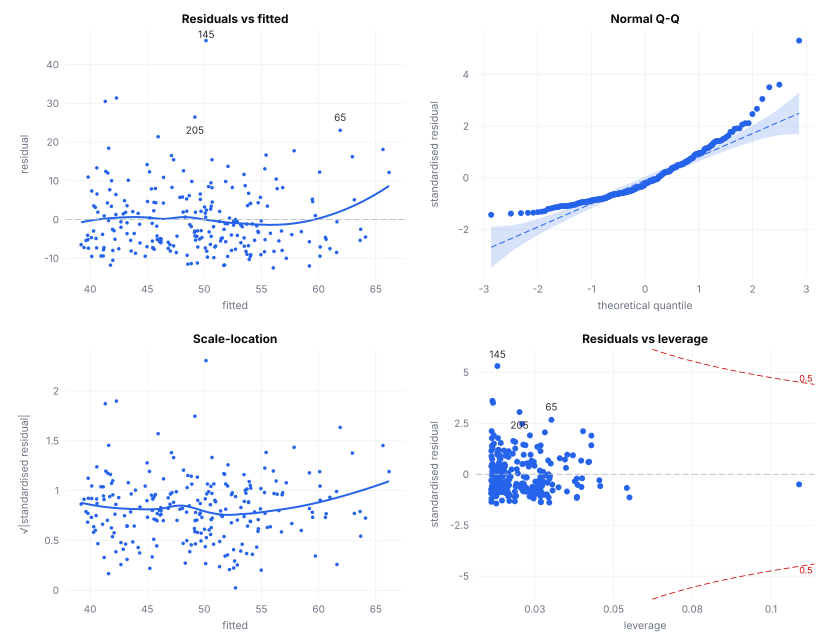

In [4]:
av.plot(basket, "diagnostics")

## 2. Which customers will order again? (scikit-learn)

Did a customer order again within 30 days of their last order? A logistic
regression and a gradient-boosting model, scored on a held-out quarter.

In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

m = 3000
customers = pd.DataFrame({
    "n_orders": rng.poisson(3, m) + 1,
    "days_since_last": rng.exponential(25, m).round(),
    "avg_basket": rng.normal(45, 12, m).round(2),
    "support_tickets": rng.poisson(0.4, m),
})
# Loyal, recent customers reorder far more often: an interaction a linear model misses.
logit = (-0.8 + 0.3 * np.log(customers.n_orders) - 0.02 * customers.days_since_last
         + 0.015 * (customers.avg_basket - 45) - 0.5 * customers.support_tickets
         + 2.0 * (customers.n_orders > 4) * (customers.days_since_last < 15))
customers["reorder"] = (rng.random(m) < 1 / (1 + np.exp(-logit))).astype(int)

X, y = customers.drop(columns="reorder"), customers.reorder
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
models = {
    "logistic": LogisticRegression(max_iter=1000),
    "boosting": HistGradientBoostingClassifier(max_depth=3, random_state=0),
}
scored = [av.from_estimator(est.fit(X_train, y_train), X_test, y_test, model_id=name)
          for name, est in models.items()]
curve = pd.concat([s["curve"] for s in scored])
metrics = pd.concat([s["summary"] for s in scored])
metrics.pivot(index="metric", columns="model_id", values="value").round(3)

model_id,boosting,logistic
metric,,
accuracy,0.751,0.728
auc,0.739,0.731
average_precision,0.660,0.637
brier,0.181,0.194
log_loss,0.548,0.576


One SVG per curve type (`by="curve_type"`); both models share each chart.
The boosting model picks up the loyal-and-recent interaction, which the
linear model cannot represent.

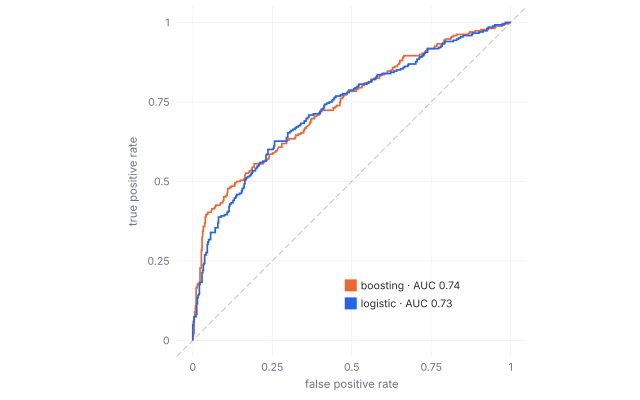

In [6]:
curves = av.plot(curve, "curve", by="curve_type")
curves["roc"]

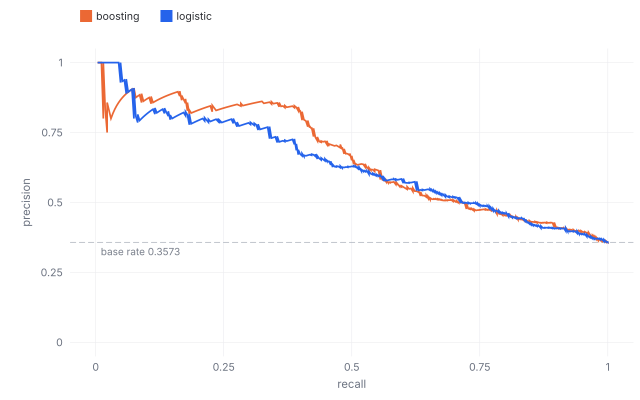

In [7]:
curves["pr"]

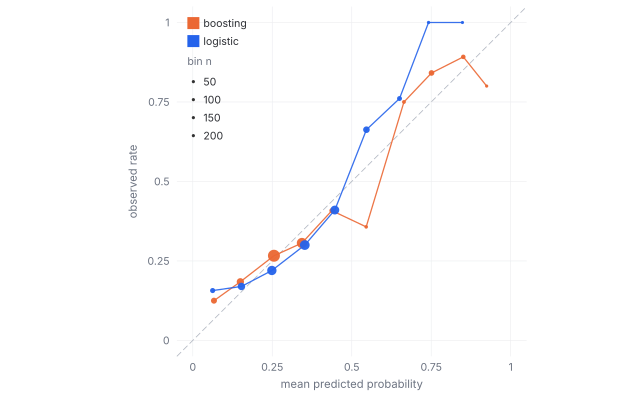

In [8]:
curves["calibration"]

The summary plot knows which way most metrics improve (higher AUC and
accuracy, lower Brier score and log loss) and marks the better model in
each; average precision is not on that list, so neither point is marked.

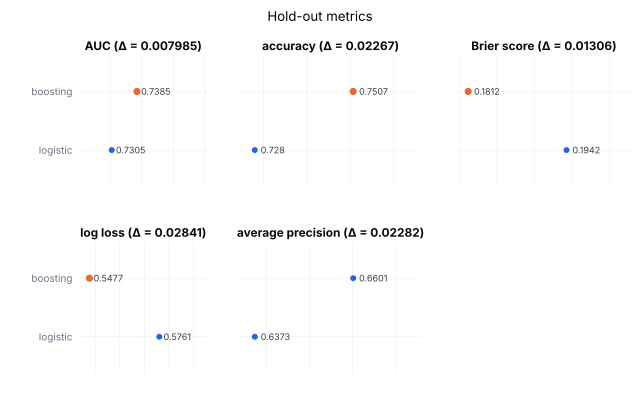

In [9]:
av.plot(metrics, "summary", title="Hold-out metrics")

## 3. Did the new checkout raise basket value? (scipy, pingouin)

The orders of part 1 were split between the old checkout (A) and a
one-page checkout (B). Welch's t-test from scipy; because baskets are
skewed, also a bootstrap interval for the difference in medians
(`scipy.stats.bootstrap`, a hand-built `tests` row); and the same t-test
from pingouin.

In [10]:
import pingouin as pg
from scipy import stats

a = orders.loc[orders.variant == "A", "basket"]
b = orders.loc[orders.variant == "B", "basket"]
median_diff = stats.bootstrap((b, a), lambda u, v, axis: np.median(u, axis) - np.median(v, axis),
                              random_state=1)
tests = pd.concat([
    av.from_scipy({"mean, Welch t (scipy)": stats.ttest_ind(b, a, equal_var=False)},
                  method="Welch t-test", estimate=b.mean() - a.mean()),
    pd.DataFrame([{"test_id": "median, bootstrap (scipy)", "method": "bootstrap",
                   "estimate": b.median() - a.median(),
                   "conf_low": median_diff.confidence_interval.low,
                   "conf_high": median_diff.confidence_interval.high}]),
    av.from_pingouin(pg.ttest(b, a), method="Welch t-test").assign(test_id="mean, Welch t (pingouin)"),
], ignore_index=True)
tests[["test_id", "method", "estimate", "conf_low", "conf_high", "p_value"]].round(4)

,test_id,method,estimate,conf_low,conf_high,p_value
0,"mean, Welch t (scipy)",Welch t-test,4.2784,1.6347,6.9221,0.0016
1,"median, bootstrap (scipy)",bootstrap,5.0200,2.1900,7.1378,NaN
2,"mean, Welch t (pingouin)",Welch t-test,4.2750,1.6300,6.9200,0.0016


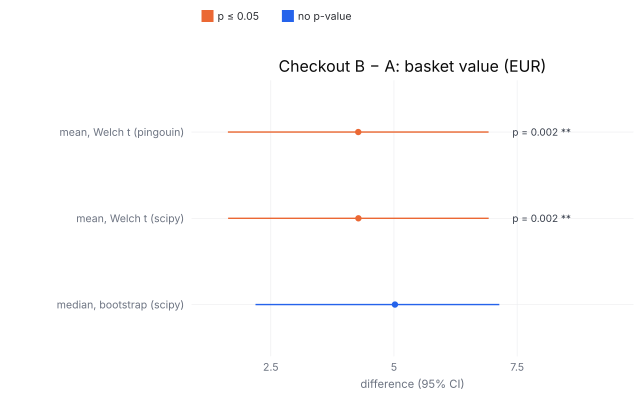

In [11]:
av.plot(tests, "tests", title="Checkout B − A: basket value (EUR)")

Basket value by discount level: pingouin's pairwise t-tests (Holm-adjusted).
They report no interval, so the plot shows the t statistics.

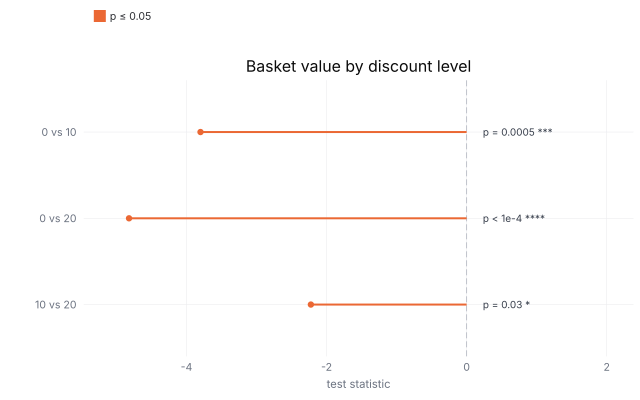

In [12]:
pairs = av.from_pingouin(
    pg.pairwise_tests(data=orders, dv="basket", between="discount", padjust="holm"),
    method="pairwise t (Holm)")
av.plot(pairs, "tests", title="Basket value by discount level")

## 4. How many orders next month? (statsforecast)

Six months of daily orders with a weekly pattern, a sale weekend and a
payment outage. AutoETS and a seasonal naive benchmark forecast 28 days with
80 % and 95 % intervals.

In [13]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive

ds = pd.date_range("2026-03-01", periods=182, freq="D")
t = np.arange(len(ds))
daily = (120 + 0.25 * t + 18 * ds.dayofweek.isin([4, 5]) - 10 * (ds.dayofweek == 0)
         + rng.normal(0, 6, len(ds)))
daily[(ds >= "2026-08-07") & (ds <= "2026-08-09")] += 45  # summer sale
daily[ds == "2026-07-09"] -= 70                           # payment outage
history = pd.DataFrame({"unique_id": "orders", "ds": ds, "y": daily.round()})

sf = StatsForecast(models=[AutoETS(season_length=7), SeasonalNaive(season_length=7)], freq="D")
fc = sf.forecast(df=history, h=28, level=[80, 95])
list(fc.columns)

['unique_id',
 'ds',
 'AutoETS',
 'AutoETS-lo-95',
 'AutoETS-lo-80',
 'AutoETS-hi-80',
 'AutoETS-hi-95',
 'SeasonalNaive',
 'SeasonalNaive-lo-80',
 'SeasonalNaive-lo-95',
 'SeasonalNaive-hi-80',
 'SeasonalNaive-hi-95']

The wide `forecast()` frame plots as it is: the extension melts
`<model>-lo-<level>` / `-hi-<level>` into one row per model and level and
draws a nested fan. Appending the history adds the observed points (the last
ten weeks here). The events are a plain table (`ds`, `kind`, `label`,
`severity`), drawn as vertical lines in the severity's colour; the planned
autumn sale lies inside the forecast.

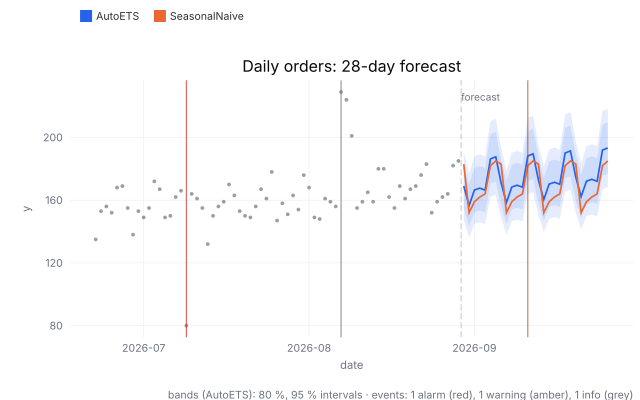

In [14]:
events = pd.DataFrame({
    "ds": pd.to_datetime(["2026-07-09", "2026-08-07", "2026-09-11"]),
    "kind": ["outage", "promo", "promo"],
    "label": ["Payment provider outage", "Summer sale", "Autumn sale (planned)"],
    "severity": ["alarm", "info", "warning"],
})
forecast = pd.concat([history[history.ds >= "2026-06-22"], fc], ignore_index=True)
av.plot(forecast, "prediction", events=events, title="Daily orders: 28-day forecast")

The same events on their own, as a timeline (`anofox_plot` picks the
`events` schema from the columns):

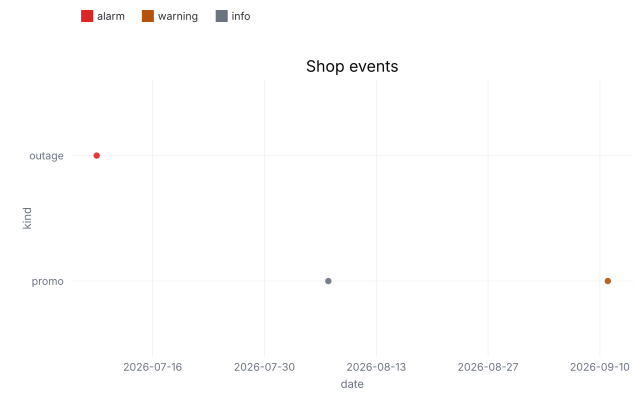

In [15]:
av.plot(events, title="Shop events")

## 5. Into a dashboard

For the browser builder, the `dashboard` CLI or locked serving, write the
tables to Parquet and read them from a dashboard `.sql` file. Re-running this
notebook refreshes the files; the dashboard shows the new numbers on its next
run.

In [16]:
from pathlib import Path

out = Path("results")
out.mkdir(exist_ok=True)
tables = {
    "basket_terms": basket["terms"], "basket_obs": basket["obs"],
    "reorder_curve": curve, "reorder_metrics": metrics,
    "checkout_tests": tests, "orders_forecast": forecast, "shop_events": events,
}
for name, df in tables.items():
    df.to_parquet(out / f"{name}.parquet", index=False)
sorted(p.name for p in out.glob("*.parquet"))

['basket_obs.parquet',
 'basket_terms.parquet',
 'checkout_tests.parquet',
 'orders_forecast.parquet',
 'reorder_curve.parquet',
 'reorder_metrics.parquet',
 'shop_events.parquet']

In [17]:
report = """\
SELECT 'Shop model report'::DASHBOARD_TITLE;

SELECT anofox_plot_terms(r), 'What drives basket value'::TITLE
FROM 'results/basket_terms.parquet' AS r WHERE term <> 'Intercept';

SELECT anofox_plot_diagnostics(r), 'Basket model diagnostics'::TITLE
FROM 'results/basket_obs.parquet' AS r;

SELECT anofox_plot_curve(r), 'Reorder model: ROC'::TITLE
FROM 'results/reorder_curve.parquet' AS r WHERE curve_type = 'roc';

SELECT anofox_plot_summary(r), 'Reorder model: hold-out metrics'::TITLE
FROM 'results/reorder_metrics.parquet' AS r;

SELECT anofox_plot_tests(r), 'Checkout B − A: basket value'::TITLE
FROM 'results/checkout_tests.parquet' AS r;

SELECT anofox_plot_prediction(r, events := (SELECT list(e) FROM 'results/shop_events.parquet' e)),
       'Daily orders: 28-day forecast'::TITLE
FROM 'results/orders_forecast.parquet' AS r;
"""
Path("shop_report.sql").write_text(report)
print(report)

SELECT 'Shop model report'::DASHBOARD_TITLE;

SELECT anofox_plot_terms(r), 'What drives basket value'::TITLE
FROM 'results/basket_terms.parquet' AS r WHERE term <> 'Intercept';

SELECT anofox_plot_diagnostics(r), 'Basket model diagnostics'::TITLE
FROM 'results/basket_obs.parquet' AS r;

SELECT anofox_plot_curve(r), 'Reorder model: ROC'::TITLE
FROM 'results/reorder_curve.parquet' AS r WHERE curve_type = 'roc';

SELECT anofox_plot_summary(r), 'Reorder model: hold-out metrics'::TITLE
FROM 'results/reorder_metrics.parquet' AS r;

SELECT anofox_plot_tests(r), 'Checkout B − A: basket value'::TITLE
FROM 'results/checkout_tests.parquet' AS r;

SELECT anofox_plot_prediction(r, events := (SELECT list(e) FROM 'results/shop_events.parquet' e)),
       'Daily orders: 28-day forecast'::TITLE
FROM 'results/orders_forecast.parquet' AS r;



`dashboard --check` runs every panel and reports the ones that fail or come
back empty; `dashboard shop_report.sql shop_report.html` renders it. The
`dashboard` binary is in the release CLI archive (or `cargo build --release
--bin dashboard`); it runs the queries through the `duckdb` CLI on `PATH`.
Set `ANOFOX_DASHBOARD` to its path if it is not on `PATH`.

In [18]:
import os
import shutil
import subprocess

repo = Path.cwd().resolve().parents[1]
dashboard = os.environ.get("ANOFOX_DASHBOARD") or shutil.which("dashboard") or next(
    (str(p) for p in (repo / "target/release/dashboard", repo / "target/debug/dashboard")
     if p.exists()), None)
if dashboard and shutil.which("duckdb"):
    check = subprocess.run([dashboard, "--check", "shop_report.sql"],
                           capture_output=True, text=True)
    print(check.stdout + check.stderr)
else:
    print("dashboard CLI or duckdb CLI not found; skipped `dashboard --check shop_report.sql`")


clean — every panel plans, runs, and renders

